# Assignment 3 - Part 1: Baseline System Analysis (Mean-Field Tipping Landscape)
**Model-Based Decision Making — EV adoption as a networked Stag Hunt**

This notebook is used for **Part 1** of the assignment. It re-uses the course code (`ev_core.py`, `ev_experiments.py`, `ev_plotting.py`) with small changes implemented to run correctly, and transferred into a notebook file (ipynb).

**What the notebook does:**
1. Build the EV Stag Hunt model on a **complete graph** ($N=200$, i.e. mean-field / well-mixed benchmark).
2. Sweep a 15 × 15 grid of initial adoption $X_0$ and initial infrastructure $I_0$, running a small ensemble of seeds per grid point ($T=150$, imitation rule).
3. Plot **Figure 1**: heatmap of mean final adoption $X^*=X(T)$ with the tipping contour, and compare it with the analytic threshold $X^*(I)=b/(a_0+\beta_I I)$.
4. Write the analysis.

**Baseline parameters:**

| Parameter | Value |
|---|---|
| $N$ | 200 (complete graph, $k_i=199$) |
| $T$ | 150 |
| $a_0$, $b$, $\beta_I$, $g_I$ | 1.0, 1.0, 2.5, 0.1 |
| Update rule | `"imitate"` |
| Initial adopters | uniformly random |

## 0. Setup
The notebook  needs **Mesa 2.x** (tested with 2.4.0). Uncomment the first line if you need to install it.

In [3]:
# if needed: !pip install "mesa<3" networkx numpy pandas matplotlib

import mesa
print("Mesa version:", mesa.__version__)


Mesa version: 2.4.0


## 1. Core model
Strategy-selection helpers, the `EVAgent`, the `EVStagHuntModel`, `set_initial_adopters` and the single-trial runner `run_simulation_trial`. 

**Model recap**
* Payoffs are degree-normalised: $\bar\pi_i(D)=b$, $\bar\pi_i(C)=x_i\,a(I)$ with $a(I)=a_0+\beta_I I$ and $x_i$ the local fraction of EV neighbours.
* Infrastructure follows $I(t+1)=\mathrm{clip}\big(I(t)+g_I\,(X(t)-I(t)),0,1\big)$.
* Imitation: every agent copies the strategy of the highest-payoff agent in its neighbourhood (itself included), all agents updating synchronously.

In [4]:

from __future__ import annotations

import os
import random
from typing import Iterable, List, Dict

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor

from mesa import Agent, Model
from mesa.time import SimultaneousActivation
from mesa.space import NetworkGrid
from mesa.datacollection import DataCollector

####################################
# Strategy selection helpers
#  - choose_strategy_imitate: copy the strategy of the highest-payoff neighbour (incl. self)
#  - choose_strategy_logit  : softmax choice (not used in Part 1)
####################################
def choose_strategy_imitate(agent, neighbors):
    """Choose strategy of the highest degree-normalised payoff neighbour (including self)."""
    candidates = neighbors + [agent]
    best = max(candidates, key=lambda a: a.payoff)   # ties -> first candidate in iteration order
    return best.strategy


def choose_strategy_logit(agent, neighbors, a_I, b, tau):
    """Choose strategy using logit / softmax choice based on degree-normalised expected payoffs."""
    if not neighbors:
        return agent.strategy
    k = len(neighbors)
    pi_C = 0.0
    pi_D = 0.0
    for other in neighbors:
        if other.strategy == "C":
            pi_C += a_I
            pi_D += b
        else:
            pi_C += 0.0
            pi_D += b
    pi_C /= k
    pi_D /= k
    denom = np.exp(pi_C / tau) + np.exp(pi_D / tau)
    P_C = np.exp(pi_C / tau) / denom if denom > 0 else 0.5
    return "C" if random.random() < P_C else "D"

In [5]:
####################################
# Agent class: one agent per graph node
#   strategy : "C" (adopt EV) or "D" (stay with ICE)
#   payoff   : degree-normalised payoff (average payoff per neighbour)
####################################
class EVAgent(Agent):
    """Single agent at a graph node."""

    def __init__(self, unique_id, model, init_strategy="D"):
        super().__init__(unique_id, model)
        self.strategy = init_strategy
        self.payoff = 0.0
        self.next_strategy = init_strategy

    def step(self):
        """Compute degree-normalised payoff from interactions with all neighbours.

        Stag Hunt pairwise payoffs:  C-C: a_I | C-D: 0 | D-C: b | D-D: b
        Round payoff is divided by the degree  ->  pi(D) = b,  pi(C) = x_i * a_I
        """
        I = self.model.infrastructure
        a0 = self.model.a0
        beta_I = self.model.beta_I
        b = self.model.b
        a_I = a0 + beta_I * I                      # effective coordination payoff, Eq. (1)

        neighbor_agents = []
        for nbr in self.model.G.neighbors(self.pos):
            neighbor_agents.extend(self.model.grid.get_cell_list_contents([nbr]))
        if not neighbor_agents:
            self.payoff = 0.0
            return

        payoff = 0.0
        for other in neighbor_agents:
            s_i = self.strategy
            s_j = other.strategy
            if s_i == "C" and s_j == "C":
                payoff += a_I
            elif s_i == "C" and s_j == "D":
                payoff += 0.0
            elif s_i == "D" and s_j == "C":
                payoff += b
            else:
                payoff += b
        self.payoff = payoff / len(neighbor_agents)   # degree normalisation, Eq. (2)

    def advance(self, strategy_choice_func="imitate"):
        """Update strategy with the selected rule (called after every agent has run step())."""
        func = strategy_choice_func if strategy_choice_func is not None else getattr(self.model, "strategy_choice_func", "imitate")

        neighbor_agents = []
        for nbr in self.model.G.neighbors(self.pos):
            neighbor_agents.extend(self.model.grid.get_cell_list_contents([nbr]))

        if func == "imitate":
            self.next_strategy = choose_strategy_imitate(self, neighbor_agents)
        elif func == "logit":
            a_I = self.model.a0 + self.model.beta_I * self.model.infrastructure
            self.next_strategy = choose_strategy_logit(self, neighbor_agents, a_I, self.model.b, getattr(self.model, "tau", 1.0))
        else:
            raise ValueError(f"Unknown strategy choice function: {func}")

        self.strategy = self.next_strategy

In [6]:
####################################
# Model class: EV Stag Hunt on a network
# Parameters: initial_ev, a0, beta_I, b, g_I, I0, seed, network_type ("random" | "BA" | "complete"),
#             n_nodes, p (ER), m (BA), collect, strategy_choice_func ("imitate" | "logit"), tau
####################################
class EVStagHuntModel(Model):
    """Mesa model for EV Stag Hunt on a network."""

    def __init__(self, initial_ev=10, a0=2.0, beta_I=3.0, b=1.0, g_I=0.1, I0=0.05, seed=None,
                 network_type="random", n_nodes=100, p=0.05, m=2, collect=True,
                 strategy_choice_func: str = "imitate", tau: float = 1.0):
        super().__init__(seed=seed)

        # Build graph
        if network_type == "BA":
            G = nx.barabasi_albert_graph(n_nodes, m, seed=seed)
        elif network_type in ["complete", "fully_connected"]:
            G = nx.complete_graph(n_nodes)
        else:
            G = nx.erdos_renyi_graph(n_nodes, p, seed=seed)
        self.G = G
        self.grid = NetworkGrid(G)
        self.schedule = SimultaneousActivation(self)   # all step() calls first, then all advance() calls

        # parameters
        self.a0 = a0
        self.beta_I = beta_I
        self.b = b
        self.g_I = g_I
        self.infrastructure = I0
        self.step_count = 0
        self.strategy_choice_func = strategy_choice_func
        self.tau = tau

        for n in self.G.nodes:
            self.G.nodes[n]["agent"] = []

        # choose initial EV nodes
        total_nodes = self.G.number_of_nodes()
        k_ev = max(0, min(initial_ev, total_nodes))
        ev_nodes = set(self.random.sample(list(self.G.nodes), k_ev))

        # create one agent per node
        uid = 0
        for node in self.G.nodes:
            init_strategy = "C" if node in ev_nodes else "D"
            agent = EVAgent(uid, self, init_strategy)
            uid += 1
            self.schedule.add(agent)
            self.grid.place_agent(agent, node)

        self.datacollector = None
        if collect:
            self.datacollector = DataCollector(
                model_reporters={"X": self.get_adoption_fraction, "I": lambda m: m.infrastructure},
                agent_reporters={"strategy": "strategy", "payoff": "payoff"},
            )

    def get_adoption_fraction(self):
        agents = self.schedule.agents
        if not agents:
            return 0.0
        return sum(1 for a in agents if a.strategy == "C") / len(agents)

    def step(self):
        """One time step: advance all agents, then update infrastructure with Eq. (5)."""
        self.schedule.step()                                   # agents update synchronously
        X = self.get_adoption_fraction()                       # adoption after the update
        I = self.infrastructure
        dI = self.g_I * (X - I)                                # infrastructure moves toward X
        self.infrastructure = float(min(1.0, max(0.0, I + dI)))  # clip to [0, 1]
        if self.datacollector is not None:
            self.datacollector.collect(self)
        self.step_count += 1


def set_initial_adopters(model, X0_frac, method="random", seed=None, high=True):
    """Set a fraction of agents to EV adopters ("random" or "degree" heuristic)."""
    rng = np.random.default_rng(seed)
    agents = model.schedule.agents
    n = len(agents)
    k = int(round(X0_frac * n))

    for a in agents:
        a.strategy = "D"
    if k <= 0:
        return

    if method == "random":
        idx = rng.choice(n, size=k, replace=False)
        for i in idx:
            agents[i].strategy = "C"
        return

    if method == "degree":
        deg = dict(model.G.degree())
        ordered_nodes = sorted(deg.keys(), key=lambda u: deg[u], reverse=high)
        chosen = set(ordered_nodes[:k])
        for a in agents:
            if a.unique_id in chosen:
                a.strategy = "C"
        return

    raise ValueError(f"Unknown method: {method}")

## 2. Single trial and the (X0, I0) sweep
`run_simulation_trial` runs one realisation and returns the final adoption $X(T)$. On the imitation rule it stops early once $X\in\{0,1\}$, which only saves time and does not change $X(T)$.

**Reproducibility (seeds):** Explicit function `make_seed(X0, I0, s)` that depends on a global `BASE_SEED`, so every run is exactly repeatable and any single run can be re-created from `(X0, I0, s)`.

In [7]:
BASE_SEED = 2026   # single global seed used to derive every per-run seed

def make_seed(X0: float, I0: float, s: int, base: int = BASE_SEED) -> int:
    """CHANGED: deterministic, documented seed for grid point (X0, I0) and ensemble member s."""
    return int((base + 1_000_003 * int(round(X0 * 10_000)) + 10_007 * int(round(I0 * 10_000)) + s) % (2**31 - 1))


def run_simulation_trial(
    X0_frac: float = 0.1, *, a0: float = 1.0, beta_I: float = 2.5, b: float = 1.0, g_I: float = 0.1,
    I0: float = 0.1, T: int = 150, network_type: str = "random", n_nodes: int = 200, p: float = 0.03,
    m: int = 3, seed: int | None = None, init_method: str = "random", high: bool = True,
    strategy_choice_func: str = "imitate", tau: float = 1.0, policy=None,
) -> float:
    """Run a single baseline simulation trial and return final adoption fraction X(T)."""
    model = EVStagHuntModel(
        initial_ev=0, a0=a0, beta_I=beta_I, b=b, g_I=g_I, I0=I0, seed=seed,
        network_type=network_type, n_nodes=n_nodes, p=p, m=m, collect=False,
        strategy_choice_func=strategy_choice_func, tau=tau,
    )
    set_initial_adopters(model, X0_frac, method=init_method, seed=seed, high=high)
    for step in range(T):
        if policy is not None:
            policy(model, step)
        model.step()
        # early stop: X = 0 or X = 1 is absorbing under imitation, so X(T) is already known
        if policy is None and strategy_choice_func == "imitate":
            x = model.get_adoption_fraction()
            if x == 0.0 or x == 1.0:
                return x
    return model.get_adoption_fraction()

In [8]:
def _row_for_I0_task(args: Dict) -> np.ndarray:
    """Worker: one heatmap row for a fixed initial infrastructure I0 (loops over X0 and seeds)."""
    I0 = args["I0"]
    X0_values = args["X0_values"]
    row = np.empty(len(X0_values), dtype=float)
    for j, X0 in enumerate(X0_values):
        finals: List[float] = []
        for s in range(args["n_seeds"]):
            seed_s = make_seed(X0, I0, s)   # CHANGED: explicit reproducible seed (was hash(...))
            x_star = run_simulation_trial(
                X0_frac=X0, a0=args["a0"], beta_I=args["beta_I"], b=args["b"], g_I=args["g_I"], I0=I0,
                T=args["T"], network_type=args["network_type"], n_nodes=args["n_nodes"], p=args["p"],
                m=args["m"], seed=seed_s, init_method=args.get("init_method", "random"),
                strategy_choice_func=args["strategy_choice_func"], tau=args["tau"],
            )
            finals.append(x_star)
        row[j] = float(np.mean(finals))
    return row


def phase_sweep_X0_vs_I0(
    X0_values: Iterable[float], I0_values: Iterable[float], *, a0=1.0, beta_I=2.5, b=1.0, g_I=0.1, T=150,
    network_type="random", n_nodes=200, p=0.03, m=3, n_seeds=10, strategy_choice_func="imitate",
    tau=1.0, init_method="random", max_workers: int | None = None, backend: str = "process",
) -> np.ndarray:
    """Matrix of mean final adoption X* over (X0, I0); shape (len(I0_values), len(X0_values))."""
    X0_values = list(X0_values)
    I0_values = list(I0_values)
    X_final = np.zeros((len(I0_values), len(X0_values)), dtype=float)

    tasks: List[Dict] = []
    for I0 in I0_values:
        tasks.append({"I0": float(I0), "X0_values": X0_values, "a0": a0, "beta_I": beta_I, "b": b, "g_I": g_I,
                      "T": T, "network_type": network_type, "n_nodes": n_nodes, "p": p, "m": m,
                      "n_seeds": n_seeds, "strategy_choice_func": strategy_choice_func, "tau": tau,
                      "init_method": init_method})

    if max_workers is None:
        max_workers = os.cpu_count() or 1

    Executor = ProcessPoolExecutor if backend == "process" and max_workers > 1 else ThreadPoolExecutor
    if max_workers > 1:
        with Executor(max_workers=max_workers) as ex:
            futures = [ex.submit(_row_for_I0_task, args) for args in tasks]
            for i, fut in enumerate(futures):
                X_final[i, :] = fut.result()
    else:
        for i, args in enumerate(tasks):
            X_final[i, :] = _row_for_I0_task(args)
    return X_final


def phase_sweep_X0_vs_I0_df(
    X0_values=None, I0_values=None, scenario_kwargs: dict | None = None, T: int = 150, n_seeds: int = 10,
    strategy_choice_func: str = "imitate", tau: float = 1.0, max_workers: int | None = None, backend: str = "process",
) -> pd.DataFrame:
    """Tidy DataFrame of mean final adoption X* over (X0, I0). Columns: ['X0', 'I0', 'X_final']."""
    if X0_values is None:
        X0_values = np.linspace(0.0, 1.0, 15)
    if I0_values is None:
        I0_values = np.linspace(0.0, 1.0, 15)

    scenario = {"a0": 1.0, "beta_I": 2.5, "b": 1.0, "g_I": 0.1, "network_type": "complete",
                "n_nodes": 200, "p": 0.03, "m": 3, "init_method": "random"}
    if scenario_kwargs:
        scenario.update(scenario_kwargs)

    X_final = phase_sweep_X0_vs_I0(
        X0_values=X0_values, I0_values=I0_values, a0=scenario["a0"], beta_I=scenario["beta_I"], b=scenario["b"],
        g_I=scenario["g_I"], T=T, network_type=scenario["network_type"], n_nodes=scenario["n_nodes"],
        p=scenario["p"], m=scenario["m"], n_seeds=n_seeds, strategy_choice_func=strategy_choice_func, tau=tau,
        init_method=scenario["init_method"], max_workers=max_workers, backend=backend,
    )
    rows = []
    for i, I0 in enumerate(I0_values):
        for j, X0 in enumerate(X0_values):
            rows.append((float(X0), float(I0), float(X_final[i, j])))
    return pd.DataFrame(rows, columns=["X0", "I0", "X_final"])

## 3. Plotting (from `ev_plotting.py`)
`plot_phase_X0_vs_I0` draws Figure 1. Compared with the original it
* shows the figure inline **and** saves it to `plots/`,
* optionally overlays the **analytic initial threshold** $X_0 = b/(a_0+\beta_I I_0)$ (white dashed) next to the numerical $X^*=0.5$ tipping contour (red).

In [9]:
def _default_plot_path(filename: str) -> str:
    plots_dir = os.path.join(os.getcwd(), "plots")
    os.makedirs(plots_dir, exist_ok=True)
    return os.path.join(plots_dir, filename)


def plot_phase_X0_vs_I0(
    phase_df: pd.DataFrame, out_path: str | None = None,
    title: str = "Figure 1: Baseline Tipping Landscape ($X^*$ over $X_0, I_0$)",
    analytic_params: dict | None = None,      # CHANGED: optional overlay of the analytic threshold
) -> str:
    """2D heatmap of final adoption X* as a function of (X0, I0). phase_df columns: ['X0','I0','X_final']"""
    pivot = phase_df.pivot(index="I0", columns="X0", values="X_final").sort_index().sort_index(axis=1)
    I0s = pivot.index.to_numpy()
    X0s = pivot.columns.to_numpy()

    fig, ax = plt.subplots(figsize=(7.5, 5.5), constrained_layout=True)
    im = ax.imshow(pivot.to_numpy(), origin="lower", extent=[X0s[0], X0s[-1], I0s[0], I0s[-1]],
                   aspect="auto", vmin=0.0, vmax=1.0, cmap="viridis")
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Final Adoption Fraction $X^*$", fontsize=11)

    # Numerical tipping boundary: contour at X* = 0.5
    X_grid, I_grid = np.meshgrid(X0s, I0s)
    try:
        cs = ax.contour(X_grid, I_grid, pivot.to_numpy(), levels=[0.5], colors="red", linewidths=2.0)
        ax.clabel(cs, inline=True, fontsize=10, fmt={0.5: "Tipping Boundary (X*=0.5)"})
    except Exception:
        pass

    # CHANGED: analytic threshold X0 = b / (a0 + beta_I * I0), Eq. (7) evaluated at the initial state
    if analytic_params is not None:
        I_fine = np.linspace(I0s[0], I0s[-1], 300)
        X_thr = analytic_params["b"] / (analytic_params["a0"] + analytic_params["beta_I"] * I_fine)
        ax.plot(np.clip(X_thr, 0, 1), I_fine, color="white", linestyle="--", linewidth=1.8,
                label=r"Analytic: $X_0=b/(a_0+\beta_I I_0)$")
        ax.legend(loc="upper right", fontsize=9, framealpha=0.85)

    ax.set_xlim(X0s[0], X0s[-1]); ax.set_ylim(I0s[0], I0s[-1])
    ax.set_xlabel("Initial Adoption Fraction $X_0$", fontsize=12)
    ax.set_ylabel("Initial Infrastructure $I_0$", fontsize=12)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.grid(True, alpha=0.15, linestyle=":")

    if out_path is None:
        out_path = _default_plot_path("figure1_phase_heatmap.png")
    fig.savefig(out_path, dpi=160)
    plt.show()          # CHANGED: show inline in the notebook as well as saving
    plt.close(fig)
    return out_path

## 4. Experiment: 15 × 15 sweep over $(X_0, I_0)$
Complete graph, $N=200$, $T=150$, $a_0=b=1$, $\beta_I=2.5$, $g_I=0.1$, imitation, random seeding.
Ensemble size is `N_SEEDS = 10` per grid point. Within one grid cell $(X_0,I_0)$ the number of initial adopters and $I_0$ are both fixed; a seed only changes *which* nodes start as adopters (and Mesa's RNG). By symmetry of $K_N$ the outcome therefore depends only on the number of initial adopters $N_{EV}=X_0N$ and $I_0$ (which sets $a(I_0)$).

Note: Multiprocessing uses `fork` (Linux/Mac); otherwise the sweep runs serially (around 4 minutes).

In [10]:
import multiprocessing as mp

# ---- experiment configuration (assignment baseline) ----
PARAMS = dict(a0=1.0, beta_I=2.5, b=1.0, g_I=0.1)
SCENARIO = dict(**PARAMS, network_type="complete", n_nodes=200, init_method="random")
T = 150
N_SEEDS = 10
GRID = 15
X0_values = np.linspace(0.0, 1.0, GRID)
I0_values = np.linspace(0.0, 1.0, GRID)

# process pool only works from a notebook with the 'fork' start method (Linux); otherwise run serially
use_procs = mp.get_start_method() == "fork"
MAX_WORKERS = (os.cpu_count() or 1) if use_procs else 1
print(f"BASE_SEED={BASE_SEED}, grid={GRID}x{GRID}, seeds/point={N_SEEDS}, workers={MAX_WORKERS}")
print("Example seeds for (X0=0.3571, I0=0.2143):", [make_seed(X0_values[5], I0_values[3], s) for s in range(3)])

BASE_SEED=2026, grid=15x15, seeds/point=10, workers=1
Example seeds for (X0=0.3571, I0=0.2143): [1444974093, 1444974094, 1444974095]


In [11]:
import time
t0 = time.time()
phase_df = phase_sweep_X0_vs_I0_df(
    X0_values=X0_values, I0_values=I0_values, scenario_kwargs=SCENARIO,
    T=T, n_seeds=N_SEEDS, strategy_choice_func="imitate",
    max_workers=MAX_WORKERS, backend="process",
)
print(f"Sweep finished in {time.time()-t0:.0f}s, {len(phase_df)} grid points")
phase_df.to_csv(_default_plot_path("part1_phase_df.csv"), index=False)   # keep raw results for the report
phase_df.head() #First five rows to check that it worked. 

Sweep finished in 171s, 225 grid points


,X0,I0,X_final
0,0.000000,0.0,0.0
1,0.071429,0.0,0.0
2,0.142857,0.0,0.0
3,0.214286,0.0,0.0
4,0.285714,0.0,0.0


### Figure 1 — Baseline tipping landscape

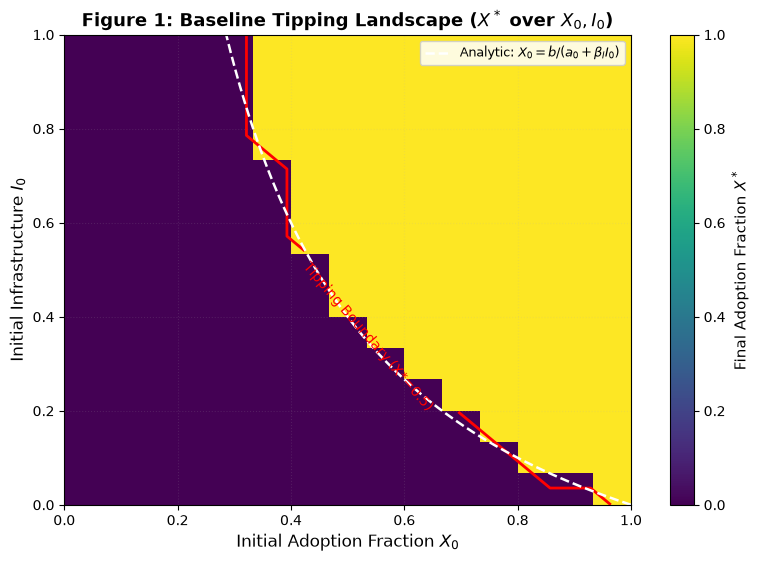

Saved: /Users/cutiegirl/Documents/GitHub/Assignment3/plots/figure1_phase_heatmap.png


In [12]:
fig1_path = plot_phase_X0_vs_I0(phase_df, analytic_params=PARAMS)
print("Saved:", fig1_path)

In [13]:
#How many initial infected nodes (people) are needed to trigger an adoption for each infrastructure level?
a0, beta_I, b = 1.0, 2.5, 1.0
for i0_check in [0.0, 0.25, 0.5, 0.75, 1.0]:
    x_crit = b / (a0 + beta_I * i0_check)
    print(f"I0 = {i0_check:.2f} -> threshold X* = {x_crit:.3f}")

I0 = 0.00 -> threshold X* = 1.000
I0 = 0.25 -> threshold X* = 0.615
I0 = 0.50 -> threshold X* = 0.444
I0 = 0.75 -> threshold X* = 0.348
I0 = 1.00 -> threshold X* = 0.286


## 5. Analysis 

**What Figure 1 shows:** The landscape is bistable and sharply divided: the graph is split into a lock-in region (purple, $X^*\approx 0$) at low $X_0$ / low $I_0$ and a tipped region (yellow, $X^*\approx 1$) at high $X_0$ / high $I_0$. There is practically no intermediate adoption level. Features of the baseline that affected the result: (i) on $K_N$ every agent observes the whole population, so all agents see the same best payoff, and (ii) the imitation rule is deterministic. After the very first update the whole population therefore copies the same strategy, giving $X(1)\in\{0,1\}$; both states are absorbing. Seeds only change *which* nodes are initial adopters, which does not matter on a symmetric graph, so the stochasticity has no influence on the results of the heatmap.

**The critical boundary:** EV adoption beats ICE when $x_i\,a(I)>b$ with $x_i\approx X$. At $t=0$, this gives the analytic threshold $X_0^*(I_0)=b/(a_0+\beta_I I_0)=1/(1+2.5\,I_0)$ (white dashed line). The numerical tipping contour (red) follows this curve closely. Above the curve, EV is the better response and cascades to full adoption; below it, ICE is the better response and adoption collapses to zero.

**How infrastructure feedback shapes the threshold:**
* *The threshold is a decreasing, convex function of $I_0$.* With no infrastructure ($I_0=0$, $a=a_0=b$) EVs are never strictly better, so $X_0\approx 1$ is needed. Each extra unit of infrastructure raises the payoff to coordination by $\beta_I=2.5$, so the required critical mass falls quickly at first (≈ 0.80 at $I_0=0.1$, 0.5 at $I_0=0.4$) and then flattens (≈ 0.29 at $I_0=1$).
* *The two levers can substitute for eachother.* Early adopters ($X_0$) and initial infrastructure ($I_0$) can compensate for each other: the system tips whenever the product $X_0\,a(I_0)$ exceeds $b$. For policy this means a lock-in point can be escaped either by seeding more early adopters or by building infrastructure ahead of demand. 
* *The feedback loop reinforces the outcome after the tip* The feedback loop, in which I moves towards X at rate g_I, reinforces whichever outcome occurs but does not shift the boundary/tipping point itself. On the complete graph with deterministic imitation, all agents switch together in the first update, so X jumps to 0 or 1 before infrastructure has time to respond. Above the boundary, I then rises towards 1. Below it, I decays towards 0, which deepens the trap.

